<a href="https://colab.research.google.com/github/smiritisi-msc26-lgtm/BPTA/blob/main/P4_bpta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

n    | m    | LP Optimal   | LP Rounded  | LP Rounded/LP Optimal   | Greedy VC   | Greedy/LP Optimal| LP Time     
--------------------------------------------------------------------------------------------------------------
10   | 10   | 4.5000       | 7           | 1.5556                  | 8           | 1.7778           | 0.00845986  
10   | 15   | 5.0000       | 5           | 1.0000                  | 8           | 1.6000           | 0.00828060  
10   | 20   | 5.0000       | 10          | 2.0000                  | 8           | 1.6000           | 0.00636687  
10   | 25   | 5.0000       | 10          | 2.0000                  | 10          | 2.0000           | 0.00993005  
10   | 30   | 5.0000       | 10          | 2.0000                  | 8           | 1.6000           | 0.00812430  
10   | 35   | 5.0000       | 10          | 2.0000                  | 8           | 1.6000           | 0.00838307  
10   | 40   | 5.0000       | 10          | 2.0000                  | 10          | 2

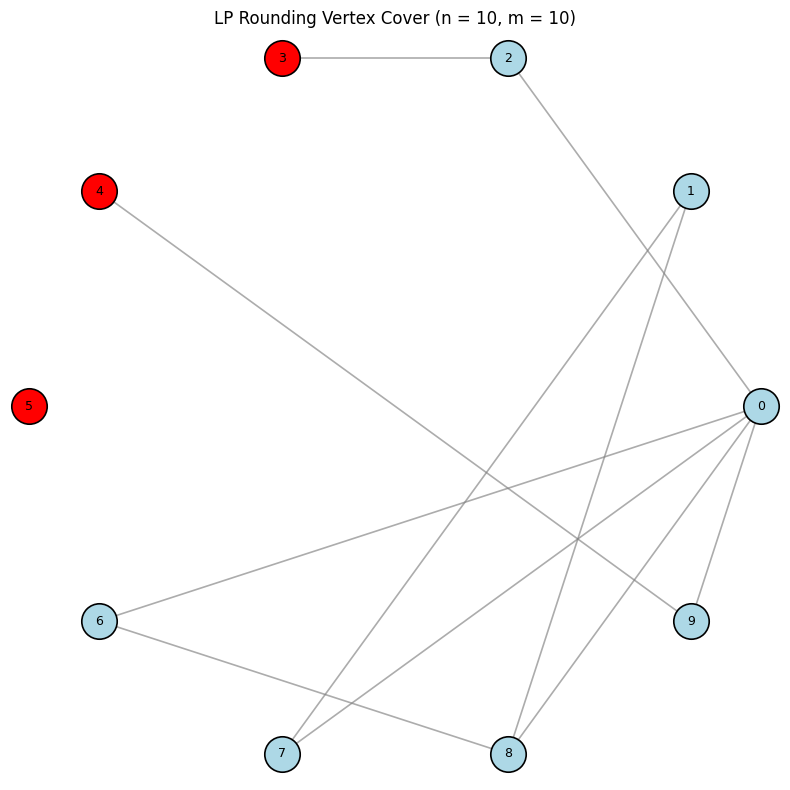

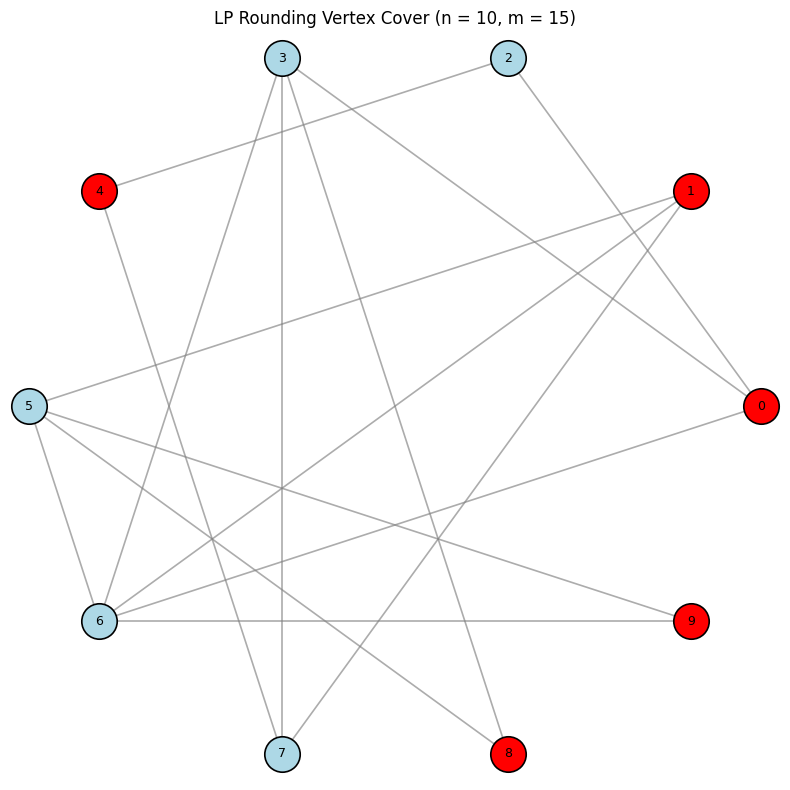

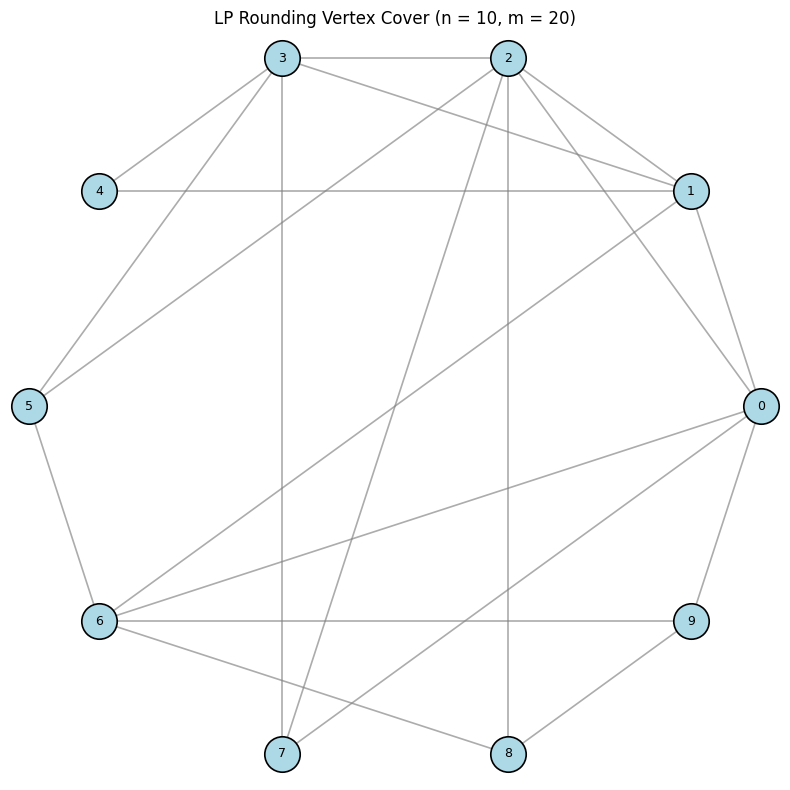

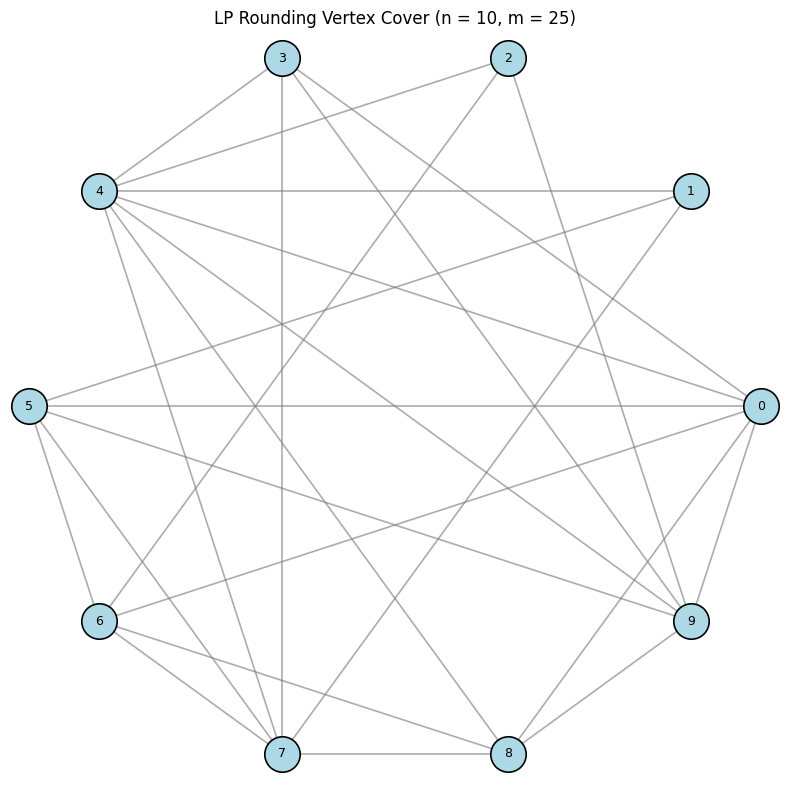

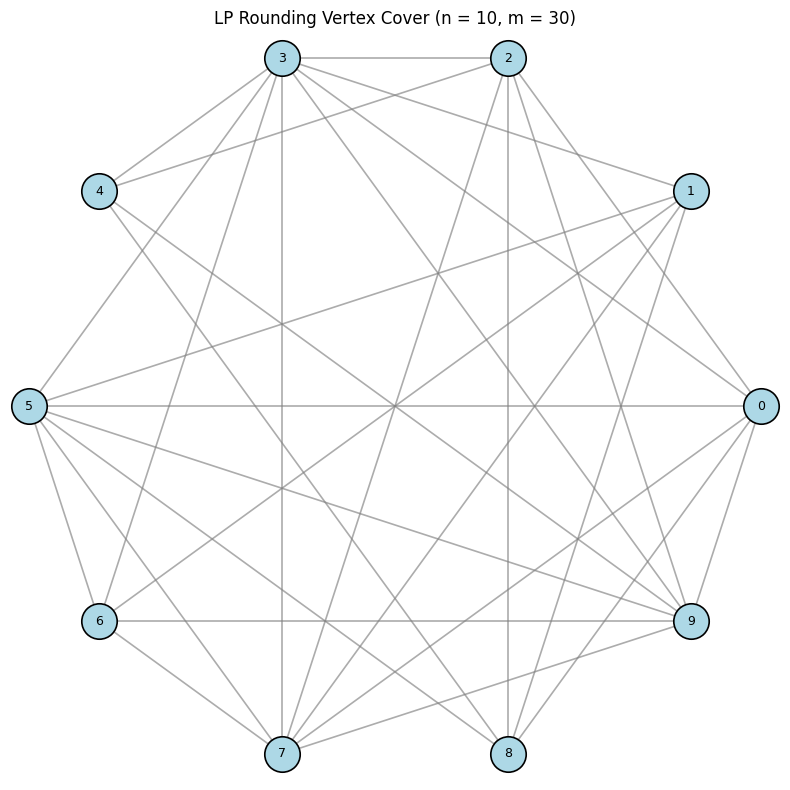

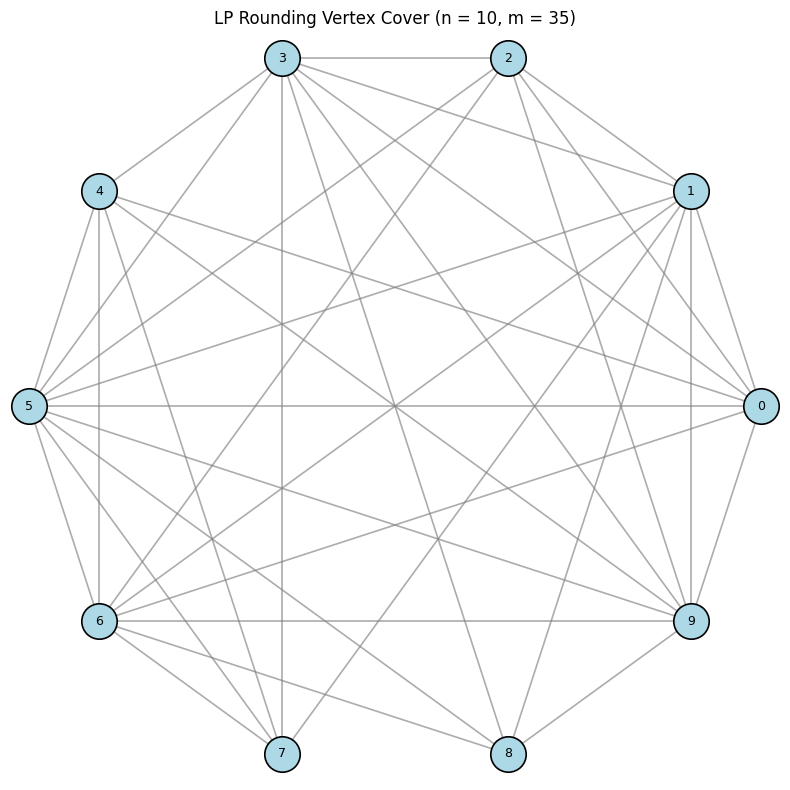

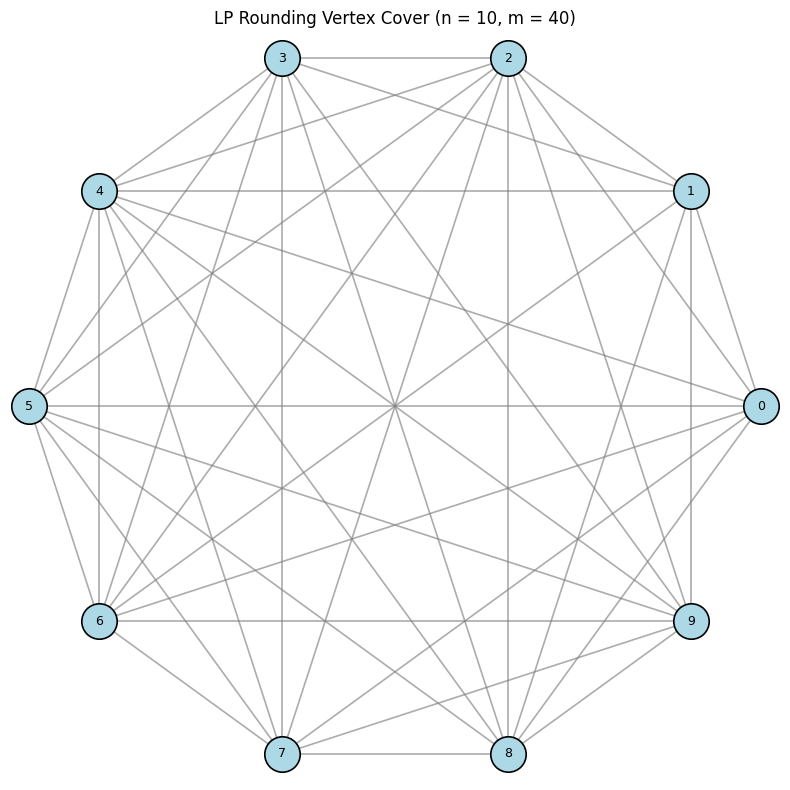

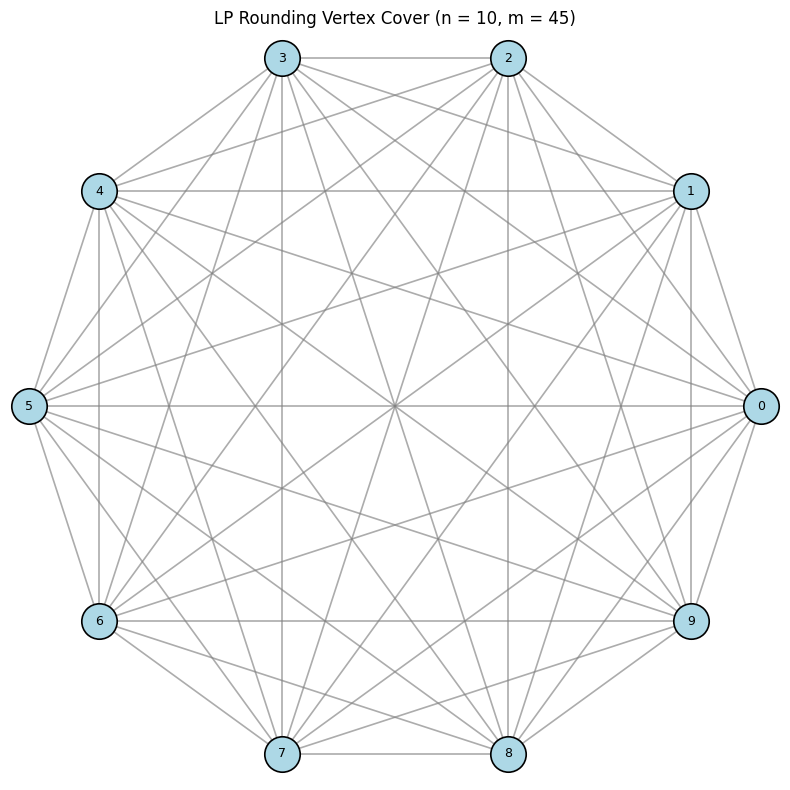

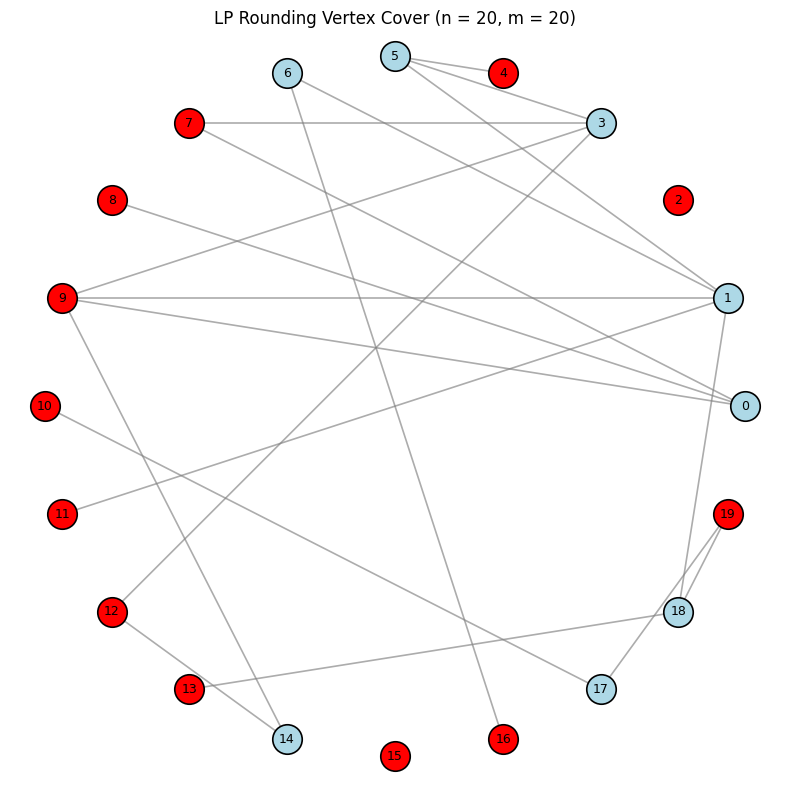

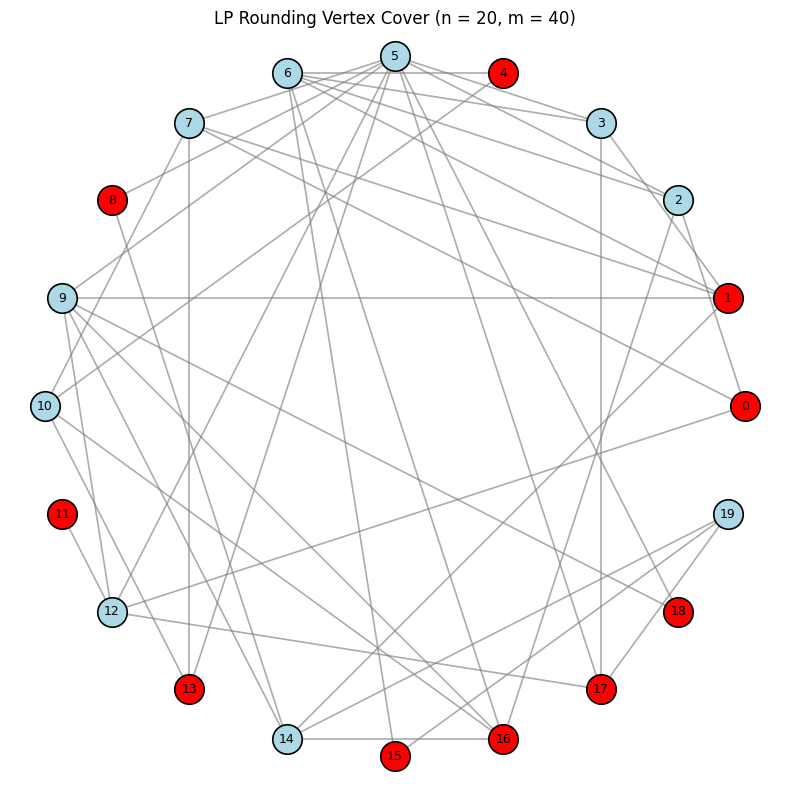

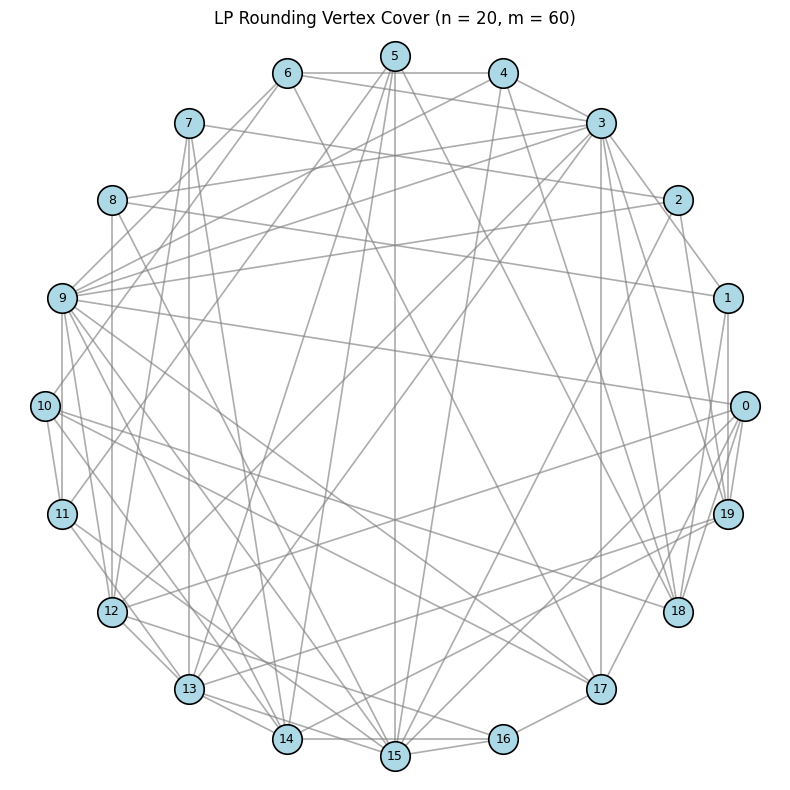

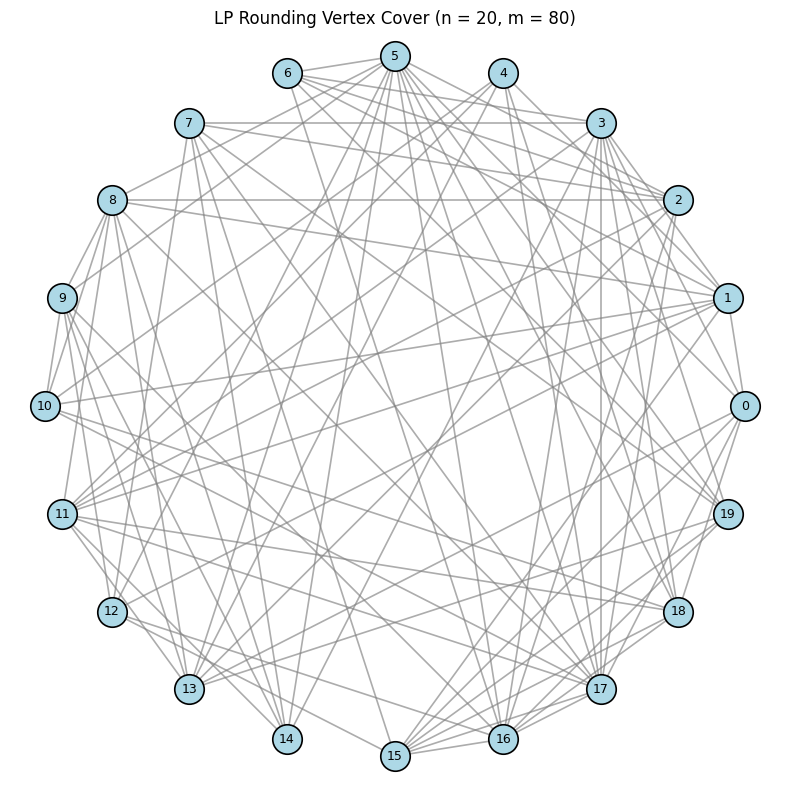

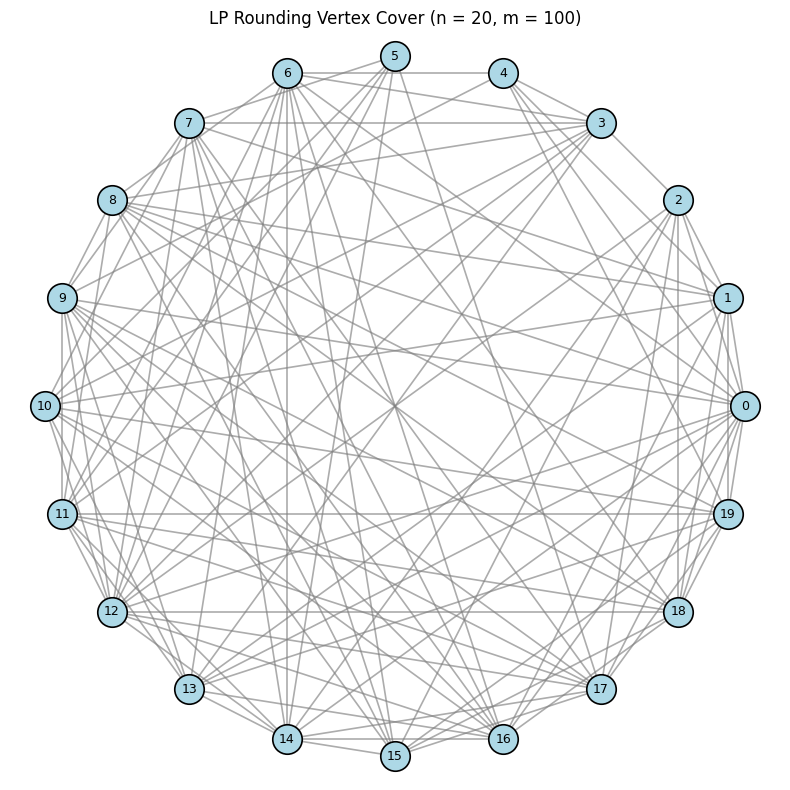

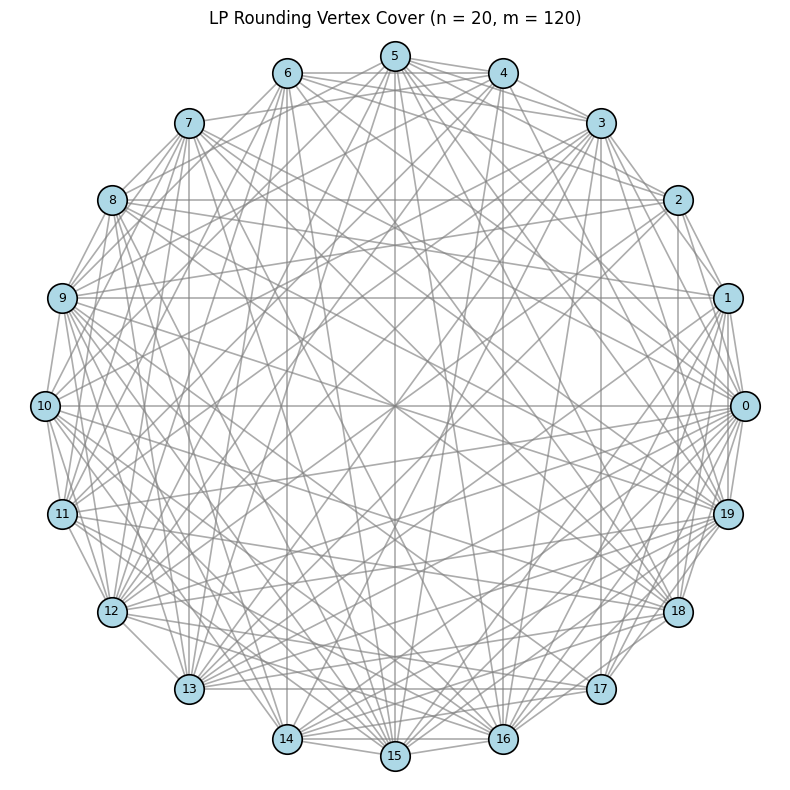

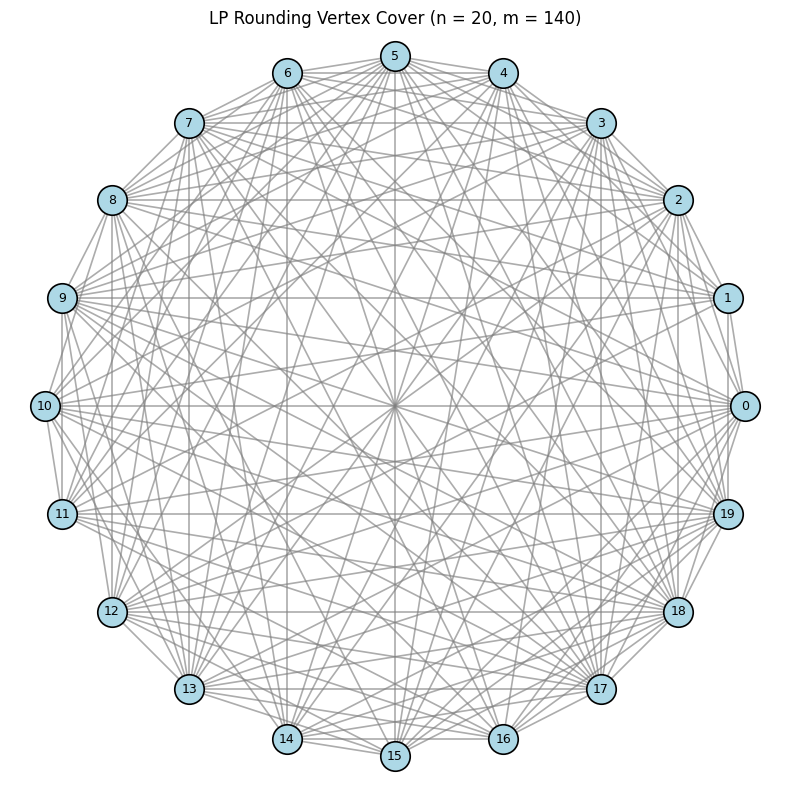

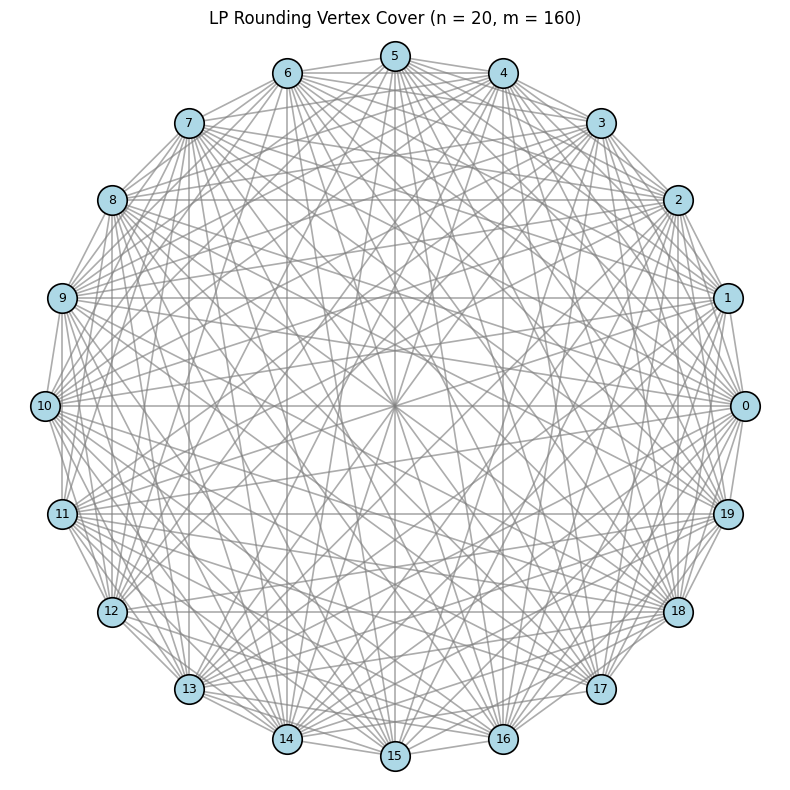

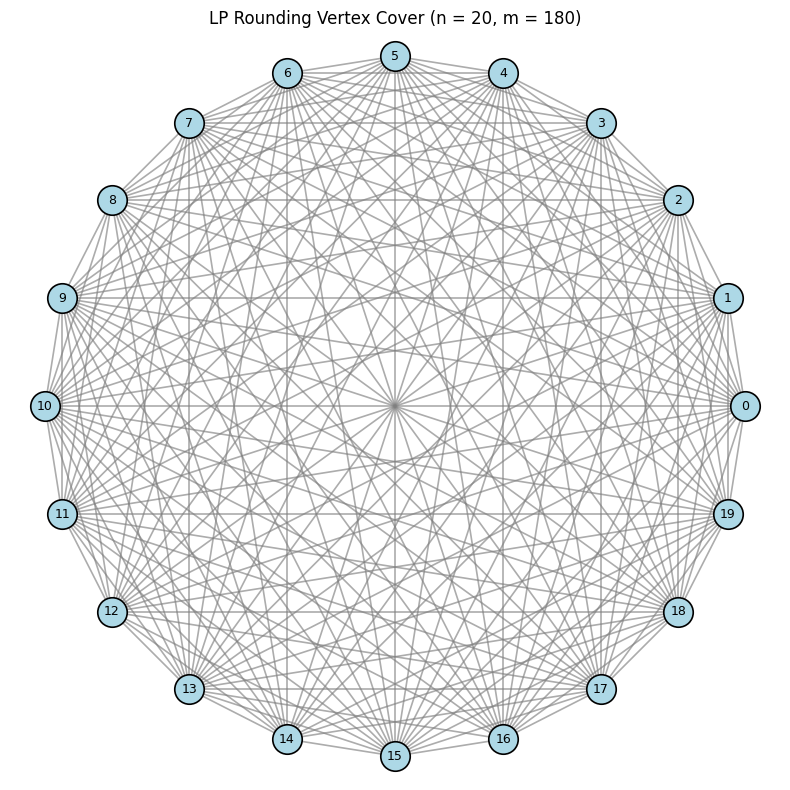

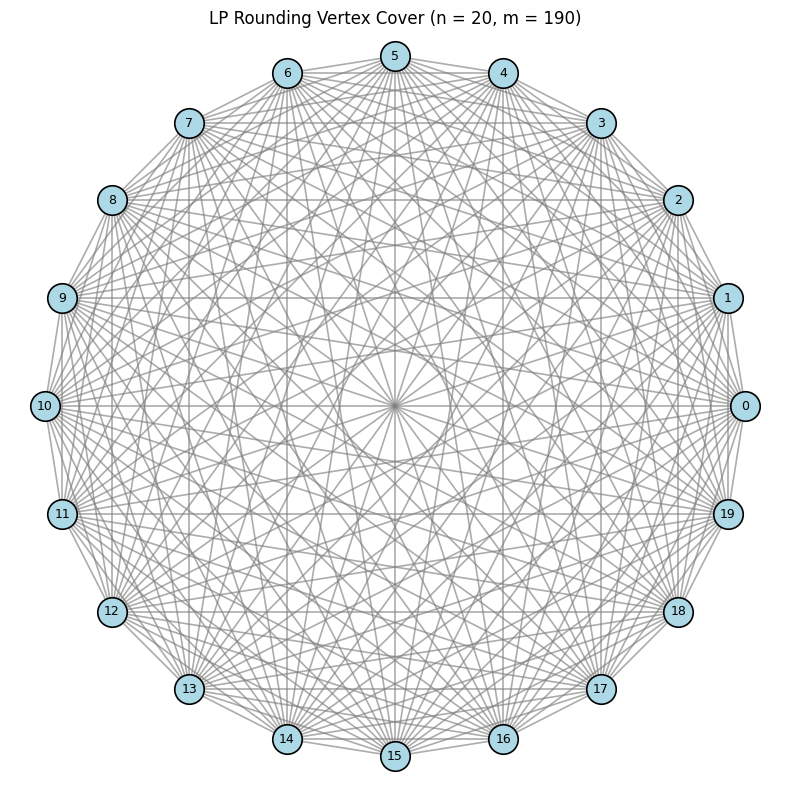

In [ ]:
import json
import csv
import ast
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

def LP_OptimalFunc(n, edges):
    c = np.ones(n)
    A = []
    b = []
    for u, v in edges:
        row = [0.0] * n
        row[u] = -1
        row[v] = -1
        A.append(row)
        b.append(-1)
    result = linprog(
        c,
        A_ub=A,
        b_ub=b,
        bounds=[(0, 1)] * n,
        method="highs"
    )
    return result.fun, result.x


def LP_Round(n, x, edges):
    cover = {i for i in range(n) if x[i] >= 0.5}
    return tuple(sorted(cover))


def plot_graph(n, edges, cover, m):
    pos = {}
    for v in range(n):
        angle = 2 * np.pi * v / n
        pos[v] = (np.cos(angle), np.sin(angle))

    plt.figure(figsize=(8, 8))

    for u, v in edges:
        plt.plot(
            [pos[u][0], pos[v][0]],
            [pos[u][1], pos[v][1]],
            color="gray",
            linewidth=1.2,
            alpha=0.65,
            zorder=1
        )
    for v in range(n):
        color = "lightblue" if v in cover else "red"

        plt.scatter(
            pos[v][0],
            pos[v][1],
            s=650 if n == 10 else 450,
            color=color,
            edgecolors="black",
            linewidths=1.2,
            zorder=2
        )
        plt.text(
            pos[v][0],
            pos[v][1],
            str(v),
            ha="center",
            va="center",
            fontsize=9,
            zorder=3
        )
    plt.title(
        "LP Rounding Vertex Cover (n = " + str(n) +
        ", m = " + str(m) + ")"
    )
    plt.axis("equal")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

graphs = []
greedy_results = {}

with open("vertex_cover_datasets.json", "r") as file:
    datasets10 = json.load(file)

with open("vertex_cover_p2_results.json", "r") as file:
    results10 = json.load(file)

for dataset in datasets10:
    graphs.append({
        "n": dataset["n"],
        "m": dataset["m"],
        "edges": [tuple(edge) for edge in dataset["edges"]]
    })

for result in results10:
    greedy_results[(result["n"], result["m"])] = result["vertex_cover_size"]

with open("P3 Dataset.csv", "r", newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        graphs.append({
            "n": int(row["n"]),
            "m": int(row["m"]),
            "edges": [
                tuple(edge)
                for edge in ast.literal_eval(row["edges"])
            ]
        })

with open("P3 Result.csv", "r", newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        greedy_results[(int(row["n"]), int(row["m"]))] = int(row["AA VC Size"])

results = []
p4_datasets = []
visualizations = []

for graph in graphs:
    n = graph["n"]
    m = graph["m"]
    edges = graph["edges"]

    start = time.perf_counter()
    LP_optimal, x = LP_OptimalFunc(n, edges)
    LP_time = time.perf_counter() - start
    LP_VC = LP_Round(n, x, edges)
    LP_Rounded = len(LP_VC)

    greedy_size = greedy_results[(n, m)]

    LP_factor = LP_Rounded/LP_optimal if LP_optimal > 0 else 0
    approx_factor = greedy_size/ LP_optimal if LP_optimal > 0 else 0

    results.append({
        "n": n,
        "m": m,
        "LP_Optimal": LP_optimal,
        "LP_Rounded": LP_Rounded,
        "LP_Rounded/LP_Optimal": LP_factor,
        "Greedy_VC_Size": greedy_size,
        "Greedy/LP_Optimal": approx_factor,
        "LP_Time": LP_time
    })

    visualizations.append({
        "n": n,
        "m": m,
        "edges": edges,
        "LP_VC": LP_VC
    })

    for v in range(n):
        p4_datasets.append({
            "n": n,
            "m": m,
            "vertex": v,
            "LP_Value": x[v],
        })


print(
    f"{'n':<5}| {'m':<5}| {'LP Optimal':<13}| "
    f"{'LP Rounded':<12}| {'LP Rounded/LP Optimal':<24}| "
    f"{'Greedy VC':<12}| {'Greedy/LP Optimal':<12}| {'LP Time':<12}"
)

print("-" * 110)

for r in results:
    print(
        f"{r['n']:<5}| {r['m']:<5}| "
        f"{r['LP_Optimal']:<13.4f}| "
        f"{r['LP_Rounded']:<12}| "
        f"{r['LP_Rounded/LP_Optimal']:<24.4f}| "
        f"{r['Greedy_VC_Size']:<12}| "
        f"{r['Greedy/LP_Optimal']:<17.4f}| "
        f"{r['LP_Time']:<12.8f}"
    )


with open("P4_vertex_cover_results.csv", "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "n",
            "m",
            "LP_Optimal",
            "LP_Rounded",
            "LP_Rounded/LP_Optimal",
            "Greedy_VC_Size",
            "Greedy/LP_Optimal",
            "LP_Time"
        ]
    )

    writer.writeheader()
    writer.writerows(results)


with open("P4 Dataset.csv", "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "n",
            "m",
            "vertex",
            "LP_Value",
        ]
    )

    writer.writeheader()
    writer.writerows(p4_datasets)

print("Vertices are blue in colour if they are part of vertex cover")
for graph in visualizations:
    plot_graph(
        graph["n"],
        graph["edges"],
        graph["LP_VC"],
        graph["m"]
    )